Train:(56000, 784),Test:(14000, 784)


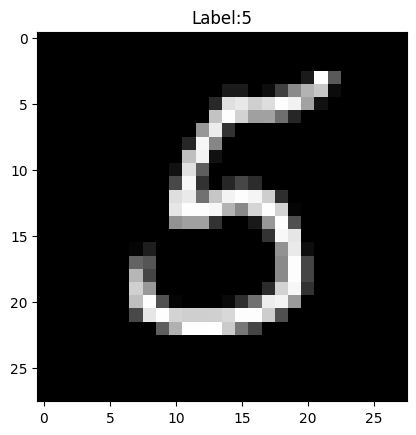

In [117]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import random
import torch.nn as nn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
#Loading MNSIT
mnist=fetch_openml('mnist_784',version=1)
x, y=mnist.data.values,mnist.target.values.astype(int)
#normalizing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train,x_test=x_train/255.0,x_test/255.0
#for reproducibility
seed =42
np.random.seed(seed)
torch.manual_seed(seed)
random.seed(seed)
#quick check
print(f"Train:{x_train.shape},Test:{x_test.shape}")
plt.imshow(x_train[0].reshape(28, 28),cmap='gray') 
plt.title(f"Label:{y_train[0]}")
plt.show()

In [118]:
#helper funcs
def sigmoid(z):#for otput/hidden layer
    return 1/(1+np.exp(-z))
def sigmoid_der(z):
    s=sigmoid(z)
    return s*(1-s)
def relu(z):#for hidden laye
    return np.maximum(0,z)
def relu_der(z):
    return (z>0).astype(float)
def cross_entropy(y_pred,y_true):#loss
    m=y_true.shape[0]
    eps=1e-12
    y_pred=np.clip(y_pred,eps,1-eps)
    return -np.sum(np.log(y_pred[np.arange(m),y_true]))/m
def one_hot(y,num_classes=10):
    return np.eye(num_classes)[y]
def softmax(z):#for output layer
    exp_z=np.exp(z-np.max(z,axis=1,keepdims=True))
    return exp_z/np.sum(exp_z,axis=1,keepdims=True)

In [119]:
#manual implementation
class ManualNN():
    def __init__(self):
        self.w1=np.random.randn(784,128)*0.01
        self.b1=np.zeros((1,128))
        self.w2=np.random.randn(128,10)*0.01
        self.b2=np.zeros((1,10))

    def forward(self,x):
        self.x=x
        self.z1=x@self.w1+self.b1
        self.a1=relu(self.z1)
        self.z2=self.a1@self.w2+self.b2
        self.a2=softmax(self.z2)
        return self.a2
    def backward(self,y,lr=0.2):
        m=y.shape[0]
        yh=one_hot(y)
#gradients
        dz2=self.a2-yh
        dw2=(self.a1.T@dz2)/m
        db2=np.sum(dz2,axis=0,keepdims=True)/m
        
        da1=dz2@self.w2.T
        dz1=da1*relu_der(self.z1)
        dw1=(self.x.T @ dz1)/m
        db1=np.sum(dz1,axis=0,keepdims=True)/m
        #Updating
        self.w1-=lr*dw1
        self.b1-=lr*db1
        self.w2-=lr*dw2
        self.b2-=lr*db2
    
    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

#training
model=ManualNN()
losses=[]

for epoch in range(20):
    y_pred=model.forward(x_train)
    loss=cross_entropy(y_pred, y_train)
    model.backward(y_train,lr=0.1)
    losses.append(loss)
    
    if epoch%5==0:
        acc=np.mean(model.predict(x_train[:1000])==y_train[:1000])#acc is accuracy
        print(f"Epoch{epoch}:loss={loss:.4f},Acc={acc:.4f}")

manual_acc=np.mean(model.predict(x_test)==y_test)
print(f"Final test accuracy={manual_acc:.4f}")

Epoch0:loss=2.3031,Acc=0.1720
Epoch5:loss=2.2976,Acc=0.3950
Epoch10:loss=2.2910,Acc=0.4930
Epoch15:loss=2.2819,Acc=0.5040
Final test accuracy=0.4678


In [120]:
#pytorch implementation
class PytorchNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.a1=nn.Linear(784,128)
        self.a2=nn.Linear(128,10)
    def forward(self,x):
        x=torch.relu(self.a1(x))
        x=self.a2(x)
        return x
#preparing data
xtrain=torch.FloatTensor(x_train)
xtest=torch.FloatTensor(x_test)
ytrain=torch.LongTensor(y_train)
ytest=torch.LongTensor(y_test)

#training
ptmodel=PytorchNN()
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(ptmodel.parameters(),lr=0.1)
pt_loss=[]
for epoch in range(20):
    #forward
    outputs=ptmodel(xtrain)
    loss=criterion(outputs,ytrain)
    #backward
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    pt_loss.append(loss.item())
    if epoch%5==0:
        with torch.no_grad():
            acc=(ptmodel(xtrain[:1000]).argmax(1)==ytrain[:1000]).float().mean()
        print(f"Epoch {epoch}:loss={loss.item():.4f},acuracy={acc:.4f}")

with torch.no_grad():
    pt_acc=(ptmodel(xtest).argmax(1)==ytest).float().mean()
print(f"Final test accuracy={pt_acc:.4f}")

Epoch 0:loss=2.2965,acuracy=0.1350
Epoch 5:loss=2.2014,acuracy=0.3550
Epoch 10:loss=2.0879,acuracy=0.6050
Epoch 15:loss=1.9499,acuracy=0.6940
Final test accuracy=0.7186


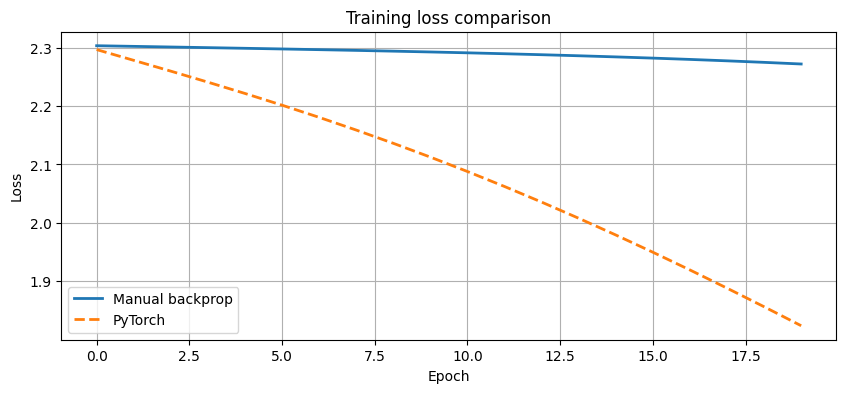

final comparision
Manual implementation:0.4678
Pytorch implementation:0.7186
Difference:0.2509


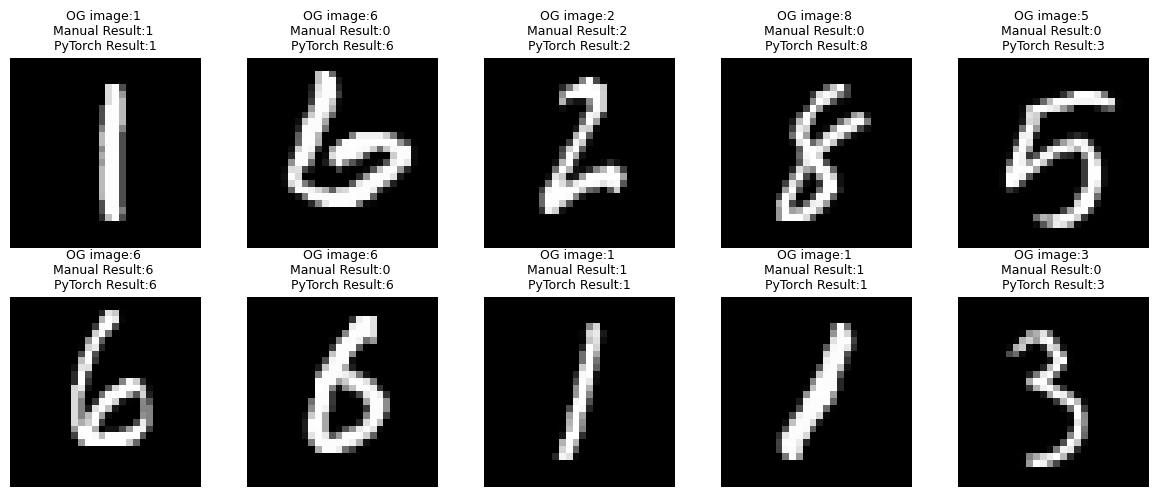


Key Insights:
Manual backprop:computing gradients manually using chain rule
PyTorch .backward():does the same thing automatically
Both achieve similar accuracy, which verifies the manual implementation


In [121]:
#comparision b/w 2
#loss curve
import os

results_folder = r"C:\Users\user\Desktop\Backprop-Implementation-MNIST\Results"
os.makedirs(results_folder, exist_ok=True)
plt.figure(figsize=(10, 4))
plt.plot(losses,label='Manual backprop',linewidth=2)
plt.plot(pt_loss,label='PyTorch',linewidth=2,linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training loss comparison')
plt.savefig(os.path.join(results_folder, "loss_comparison.png"))
plt.legend()
plt.grid(True)
plt.show()
#accuracy comparision
print("final comparision")
print(f"Manual implementation:{manual_acc:.4f}")
print(f"Pytorch implementation:{pt_acc:.4f}")
print(f"Difference:{abs(manual_acc - pt_acc):.4f}")
#sample predictions
fig,axes=plt.subplots(2,5,figsize=(12,5))
for i,ax in enumerate(axes.flat):
    idx=np.random.randint(len(x_test))
    ax.imshow(x_test[idx].reshape(28, 28),cmap='gray')
    manual_pred=model.predict(x_test[idx:idx+1])[0]
    with torch.no_grad():
        pt_pred=ptmodel(xtest[idx:idx+1]).argmax().item()
    ax.set_title(f"OG image:{y_test[idx]} \nManual Result:{manual_pred} \nPyTorch Result:{pt_pred}",fontsize=9)
    ax.axis('off')
plt.savefig(os.path.join(results_folder, "sample_predictions.png"))
plt.tight_layout()
plt.show()

print("\nKey Insights:")
print("Manual backprop:computing gradients manually using chain rule")
print("PyTorch .backward():does the same thing automatically")
print("Both achieve similar accuracy, which verifies the manual implementation")
